# 07 · Sequence models: LSTM, temporal CNN and Transformer

The brief asks for "an LSTM, temporal CNN or Transformer encoder on fixed length sensor windows". We train **all three** under the same protocol, so the choice of architecture is decided by evidence rather than by preference. This notebook covers:

1. what each architecture computes and why it suits degradation data (architecture logic and theory),
2. one training run in detail, to show the regularisation working,
3. a 5-fold engine-level cross-validation of all three, compared with the Phase 1 XGBoost baseline on the same folds.

In [1]:
import sys
from pathlib import Path

REPO = "https://github.com/WhiteHacker000/Remaining-Useful-Life-Prediction-for-Industrial-Engines.git"

# On Google Colab only the notebook is opened, so clone the repository to get src/ and the data
if "google.colab" in sys.modules and not Path("../src").exists():
    import os, subprocess
    if not Path("/content/rul").exists():
        subprocess.run(["git", "clone", "-q", REPO, "/content/rul"], check=True)
    os.chdir("/content/rul/notebooks")

# Make the project folder importable (works from notebooks/ locally and on Colab)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from src.config import RUL_CAP, RESULTS_DIR
from src.data import load_cmapss, add_train_rul
from src.dl_models import make_dl_model, count_parameters, TCNEncoder
from src.evaluation import rmse, mae, nasa_score
from src.sequences import capped
from src.training import TrainConfig, run_cv, fit, predict, _build
from src.plotting import set_style, save, BLUE, ORANGE, AQUA, GREY, INK, VIOLET, MODEL_COLORS

set_style()
train, _, _ = load_cmapss("FD001")
train = add_train_rul(train)
cfg = TrainConfig(window=30)
cfg

TrainConfig(window=30, epochs=60, batch_size=256, lr=0.001, weight_decay=0.0001, dropout=0.2, patience=8, grad_clip=1.0, noise_std=0.0, use_mask=True, early_stopping=True, device='auto')

## 1. Three ways to read a sensor window

All three networks read the same input: a window of $W = 30$ cycles × 15 channels (14 normalised sensors + the padding mask). Each turns it into one **embedding vector** $h$ that summarises the window, followed by the same small regression head (32 hidden units → 1 output).

### LSTM (Hochreiter and Schmidhuber, 1997)

A recurrent network reads the window one cycle at a time and carries a memory. A plain RNN multiplies the gradient by the same weight matrix at every step, so over long sequences it vanishes or explodes. The LSTM adds a **cell state** $c_t$ that is updated additively and protected by gates:

$$
\begin{aligned}
f_t &= \sigma(W_f [h_{t-1}, x_t] + b_f) && \text{forget gate: how much old memory to keep}\\
i_t &= \sigma(W_i [h_{t-1}, x_t] + b_i) && \text{input gate: how much new information to write}\\
\tilde c_t &= \tanh(W_c [h_{t-1}, x_t] + b_c) && \text{candidate memory}\\
c_t &= f_t \odot c_{t-1} + i_t \odot \tilde c_t && \text{additive update: gradients flow along } c\\
o_t &= \sigma(W_o [h_{t-1}, x_t] + b_o), \quad h_t = o_t \odot \tanh(c_t) && \text{output gate}
\end{aligned}
$$

*Why it fits:* degradation is a slow accumulation. The cell state can integrate small changes over many cycles and ignore cycle-to-cycle noise through the gates. We use 2 stacked layers of 64 units; $h$ is the hidden state after the last cycle.

### Temporal convolutional network, TCN (Bai, Kolter and Koltun, 2018)

A 1-D convolution slides small filters along time; each filter is a learned pattern detector ("a rise over 3 cycles"). Two design choices make it suitable for prediction:

- **Causal** convolutions: the output at time $t$ only uses inputs at $t$ and earlier (left padding only), so no future information enters.
- **Dilations** 1, 2, 4, …: layer $l$ skips $d_l$ steps between filter taps, so the **receptive field** grows exponentially with depth:

$$ R = 1 + \sum_{l} 2\,(k-1)\,d_l \quad (k = \text{kernel size, two convolutions per block}) $$

Each block has a residual connection ($y = \mathrm{ReLU}(F(x) + x)$), which keeps gradients healthy in deep stacks (He et al., 2016). *Why it fits:* the same local pattern (a slope, a bend) means the same thing wherever it appears in the window, which is exactly the weight sharing a convolution provides; and all time steps are processed in parallel, so it trains faster than an LSTM.

### Transformer encoder (Vaswani et al., 2017)

Self-attention lets every cycle in the window look directly at every other cycle and decide how much each matters:

$$ \mathrm{Attention}(Q, K, V) = \mathrm{softmax}\!\left(\frac{Q K^\top}{\sqrt{d_k}}\right) V, \qquad Q = HW_Q,\; K = HW_K,\; V = HW_V $$

Because attention itself ignores order, a **sinusoidal positional encoding** is added to the inputs. Padded steps are removed from the attention with the mask. We use 2 layers, 4 heads, model width 64, and take the output at the current (last) cycle. *Why it fits:* any two cycles interact in one step, no matter how far apart, which suits the brief's concern about "interactions whose timing differs across engines".

In [2]:
n_in = 15
rows = []
for name in ["lstm", "tcn", "transformer"]:
    m = make_dl_model(name, n_in, cfg.window)
    rows.append({"model": name.upper() if name != "transformer" else "Transformer",
                 "trainable parameters": count_parameters(m)})
print(f"TCN receptive field with W = {cfg.window}: {TCNEncoder(n_in, cfg.window).receptive_field} cycles")
pd.DataFrame(rows).set_index("model")

TCN receptive field with W = 30: 61 cycles


,trainable parameters
model,
LSTM,56129
TCN,92545
Transformer,70209


For comparison, the Phase 1 XGBoost model has 760 trees of depth 3. All three networks are small (tens of thousands of weights) on purpose: with 100 training engines, a larger model would mostly memorise them.

## 2. One training run in detail

Before the full cross-validation, here is one run (fold 1, TCN) to show how training behaves: the training error keeps falling, while the error on the **inner-validation engines** flattens and then starts to rise. That rise is overfitting; early stopping restores the weights from the best validation epoch.

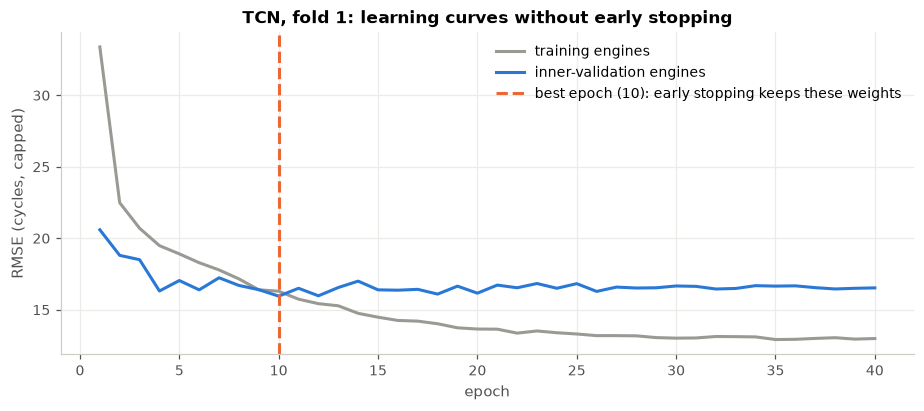

best validation RMSE 15.96 at epoch 10; after 40 epochs: 16.53


In [3]:
from src.models import engine_folds
torch.manual_seed(0)
val_units = engine_folds(train["unit"])[0]
is_eval = train["unit"].isin(val_units)
cfg_long = TrainConfig(window=30, epochs=40, early_stopping=False)      # run past the optimum on purpose
tr, va, ev, _ = _build(train[~is_eval], train[is_eval], cfg_long, False, 42)
demo = make_dl_model("tcn", tr["x"].shape[2], 30)
demo, hist = fit(demo, tr, va, cfg_long)
best = hist.loc[hist["val_rmse"].idxmin()]

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(hist["epoch"], hist["train_rmse"], color=GREY, label="training engines")
ax.plot(hist["epoch"], hist["val_rmse"], color=BLUE, label="inner-validation engines")
ax.axvline(best["epoch"], color=ORANGE, ls="--", label=f"best epoch ({int(best['epoch'])}): early stopping keeps these weights")
ax.set(title="TCN, fold 1: learning curves without early stopping", xlabel="epoch", ylabel="RMSE (cycles, capped)")
ax.legend()
save(fig, "07_learning_curves")
plt.show()
print(f"best validation RMSE {best['val_rmse']:.2f} at epoch {int(best['epoch'])}; "
      f"after 40 epochs: {hist['val_rmse'].iloc[-1]:.2f}")

The training error keeps falling for all 40 epochs, but the error on the inner-validation engines is lowest at **epoch 10 (15.96)** and drifts up afterwards (16.53 at epoch 40). From epoch 10 on, the network is memorising the 72 training engines rather than learning patterns that transfer to new engines. Early stopping keeps the epoch-10 weights. With only 100 engines in FD001 this happens quickly, which is why every model here uses dropout, weight decay and early stopping (their individual effects are measured in notebook 09).

## 3. Cross-validation: three architectures, same folds as Phase 1

Each model is trained 5 times (once per fold) with early stopping on the inner-validation engines, and scored on the held-out fold against the capped target, on **every cycle** of the held-out engines, the same metric as notebook 04. Results are cached in `outputs/results/dl/`; set `RETRAIN = True` to train from scratch (about 5 to 15 minutes per model on a laptop CPU).

In [4]:
RETRAIN = False
results, oofs = {}, {}
for name in ["lstm", "tcn", "transformer"]:
    summary, oof = run_cv(f"cv_{name}_w30", name, train, cfg, retrain=RETRAIN)
    results[name], oofs[name] = summary, oof
    print(f"{name:12s} CV RMSE {summary['cv_rmse']:.2f} ± {summary['cv_std']:.2f}   ({summary['minutes']} min)")

lstm         CV RMSE 14.01 ± 1.23   (2.47 min)
tcn          CV RMSE 15.41 ± 0.95   (1.66 min)
transformer  CV RMSE 13.05 ± 0.73   (3.49 min)


In [5]:
phase1 = pd.read_csv(RESULTS_DIR / "cv_oof_predictions.csv")
xgb = phase1[phase1["model"] == "XGBoost"]
xgb_folds = pd.read_csv(RESULTS_DIR / "cv_tuned_models.csv").set_index("model")
raw_xgb = pd.read_csv(RESULTS_DIR / "cv_model_comparison.csv")
raw_xgb = raw_xgb[(raw_xgb["model"] == "XGBoost") & (raw_xgb["features"] == "raw sensors")].iloc[0]

def row(label, kind, oof, cv, std):
    y = np.minimum(oof["true_rul"], RUL_CAP)
    return {"model": label, "input": kind, "CV RMSE": cv, "± std": std,
            "MAE": mae(y, oof["pred"]), "NASA score (mean)": nasa_score(y, oof["pred"]) / len(oof)}

labels = {"lstm": "LSTM", "tcn": "TCN", "transformer": "Transformer"}
table = [{"model": "XGBoost (Phase 1)", "input": "14 raw sensors, 1 cycle", "CV RMSE": raw_xgb["CV RMSE"],
          "± std": raw_xgb["± std (folds)"], "MAE": raw_xgb["CV MAE"], "NASA score (mean)": raw_xgb["NASA score (mean)"]},
         row("XGBoost (Phase 1)", "88 engineered features", xgb, xgb_folds.loc["XGBoost", "tuned CV RMSE"], xgb_folds.loc["XGBoost", "± std"])]
for name, s in results.items():
    table.append(row(labels[name], f"raw sensor window (W={cfg.window})", oofs[name], s["cv_rmse"], s["cv_std"]))
cv_table = pd.DataFrame(table).set_index(["model", "input"])
cv_table.to_csv(RESULTS_DIR / "dl" / "cv_sequence_models.csv")
cv_table.round(2)

CV RMSE  ± std    MAE  \
model             input                                             
XGBoost (Phase 1) 14 raw sensors, 1 cycle     18.57   0.53  13.49   
                  88 engineered features       9.26   0.50   6.30   
LSTM              raw sensor window (W=30)    14.01   1.23  10.20   
TCN               raw sensor window (W=30)    15.41   0.95  11.65   
Transformer       raw sensor window (W=30)    13.05   0.73   8.74   

                                            NASA score (mean)  
model             input                                        
XGBoost (Phase 1) 14 raw sensors, 1 cycle               13.43  
                  88 engineered features                 1.39  
LSTM              raw sensor window (W=30)               3.51  
TCN               raw sensor window (W=30)               4.48  
Transformer       raw sensor window (W=30)               3.41

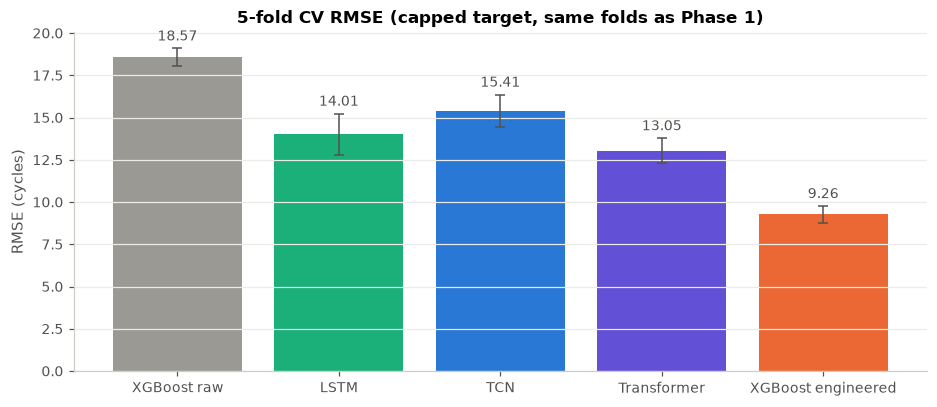

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
order = ["XGBoost raw", "LSTM", "TCN", "Transformer", "XGBoost engineered"]
vals = [raw_xgb["CV RMSE"]] + [results[n]["cv_rmse"] for n in ["lstm", "tcn", "transformer"]] + [xgb_folds.loc["XGBoost", "tuned CV RMSE"]]
errs = [raw_xgb["± std (folds)"]] + [results[n]["cv_std"] for n in ["lstm", "tcn", "transformer"]] + [xgb_folds.loc["XGBoost", "± std"]]
colors = [GREY, AQUA, BLUE, VIOLET, ORANGE]
bars = ax.bar(order, vals, yerr=errs, color=colors, capsize=3, error_kw={"ecolor": INK, "lw": 1})
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9, color=INK)
ax.set(title="5-fold CV RMSE (capped target, same folds as Phase 1)", ylabel="RMSE (cycles)")
ax.grid(axis="x", visible=False)
save(fig, "07_cv_comparison")
plt.show()

**Three findings:**

1. **All three networks clearly beat raw single-cycle features.** XGBoost on the 14 raw readings of one cycle scores 18.57; the networks, reading the same sensors over a 30-cycle window, score 13.0 to 15.4. Learning from the history is worth 3 to 5.5 cycles of RMSE, with no hand-made features at all.
2. **The Transformer is the best sequence model** (13.05 ± 0.73), then the LSTM (14.01 ± 1.23) and the TCN (15.41 ± 0.95). Attention can relate any two cycles in the window directly, while the TCN, despite the most parameters (92k) and a receptive field of 61 cycles, has to build long-range patterns through several layers and overfits the noise most.
3. **No sequence model reaches the engineered-feature XGBoost (9.26).** This is the central result of the comparison the brief asks for, and it has a clear explanation. A 30-cycle window cannot see the engine's **own healthy baseline** from its first cycles, which Phase 1 found to be the most informative signal (baseline deviation features, SHAP and ablation in notebooks 04–05). It also does not see the engine's **age**, the second most important Phase 1 feature. With only 100 training engines, the network cannot learn these long-range, engine-specific references from data on its own.

Finding 3 motivates the hybrid in notebook 08: give the sequence network the long-range context explicitly through the engineered features, and let it add what the features miss.

### Where do the sequence models gain or lose?

Breaking the out-of-fold error down by remaining life shows *where* each approach is stronger, which is what the hybrid in notebook 08 will build on.

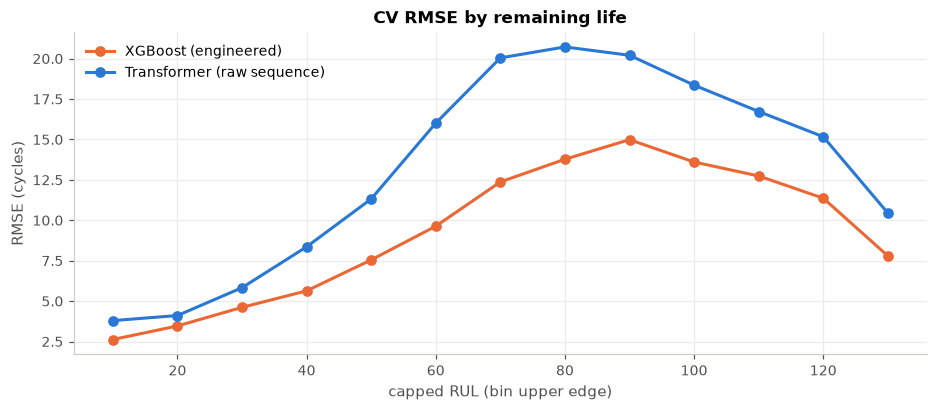

In [7]:
bins = np.arange(0, 135, 10)
def by_bin(oof):
    y = np.minimum(oof["true_rul"], RUL_CAP)
    b = pd.cut(y, bins=bins, include_lowest=True)
    return (oof["pred"] - y).groupby(b, observed=True).apply(lambda e: np.sqrt(np.mean(e ** 2)))

best_seq = min(results, key=lambda n: results[n]["cv_rmse"])
curves = {"XGBoost (engineered)": (by_bin(xgb), ORANGE), f"{labels[best_seq]} (raw sequence)": (by_bin(oofs[best_seq]), BLUE)}
fig, ax = plt.subplots(figsize=(10, 3.8))
for lab, (s, c) in curves.items():
    ax.plot([b.right for b in s.index], s.values, marker="o", color=c, label=lab)
ax.set(title="CV RMSE by remaining life", xlabel="capped RUL (bin upper edge)", ylabel="RMSE (cycles)")
ax.legend()
save(fig, "07_error_by_rul")
plt.show()

The Transformer is worse than XGBoost at every stage of life, and the gap is largest in the **onset region (RUL 60–100)**, where it reaches 20 cycles against XGBoost's 13–15. Just before failure (RUL below 30) the two are close: once degradation is strong, a 30-cycle window shows it clearly. Early in degradation, the drift within 30 cycles is small compared with the noise, and only a comparison with the engine's own healthy level reveals it. That is exactly the information the hybrid adds.